# Task 1: Import Required Libraries

In this task, the required Python libraries for data analysis, visualization, and machine learning are imported.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Task 2: Load and Explore the Dataset

The Medical Insurance Dataset contains information about policyholders and their medical insurance costs.

Columns:
- age: Age of the client
- sex: Gender of the client
- bmi: Body Mass Index
- children: Number of dependents
- smoker: Smoking status
- region: Geographic region
- charges: Medical insurance cost (target variable)

In [15]:
import pandas as pd

# Load dataset
df = pd.read_csv("insurance.csv")

# Display first 5 rows
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [16]:
# Dataset structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [17]:
print("Dataset Shape:", df.shape)
print("Number of Records:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (1338, 7)
Number of Records: 1338
Number of Columns: 7


In [18]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## Findings

### Number of Records
The dataset contains 1338 records and 7 columns.

### Data Types
The dataset contains both numerical and categorical variables.

Numerical variables:
- age
- bmi
- children
- charges

Categorical variables:
- sex
- smoker
- region

### Missing Values
No missing values were found in the dataset. This means the dataset is complete and does not require missing value treatment before analysis.

# Task 3: Exploratory Data Analysis (EDA)

EDA helps us understand relationships between variables and identify factors that influence insurance charges.

We will investigate:

1. Distribution of insurance charges
2. Impact of smoking status
3. Relationship between age and charges
4. Correlation between variables

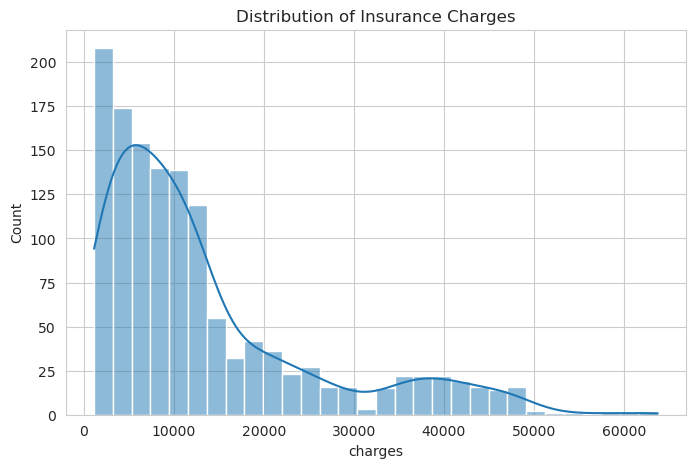

In [19]:
plt.figure(figsize=(8,5))
sns.histplot(df["charges"], bins=30, kde=True)
plt.title("Distribution of Insurance Charges")
plt.show()

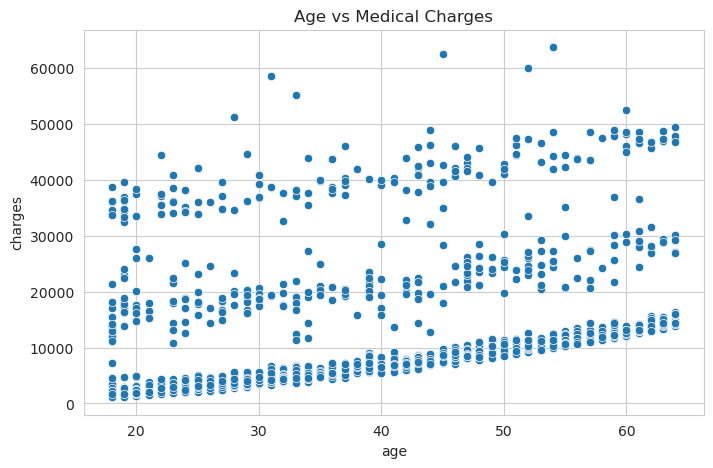

In [20]:
plt.figure(figsize=(8,5))
sns.scatterplot(x="age", y="charges", data=df)
plt.title("Age vs Medical Charges")
plt.show()

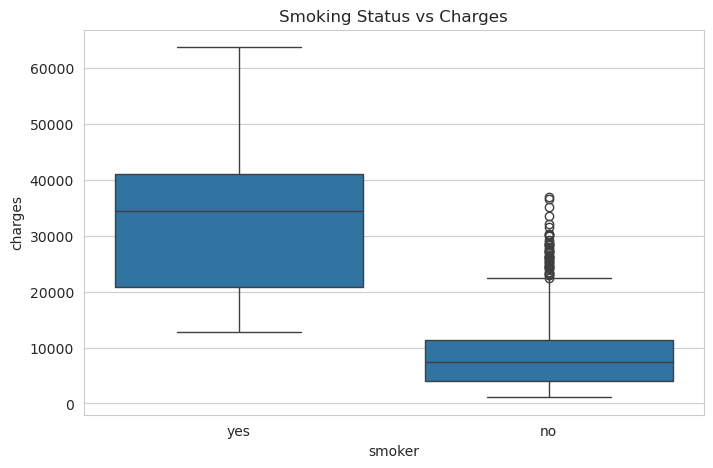

In [21]:
plt.figure(figsize=(8,5))
sns.boxplot(x="smoker", y="charges", data=df)
plt.title("Smoking Status vs Charges")
plt.show()

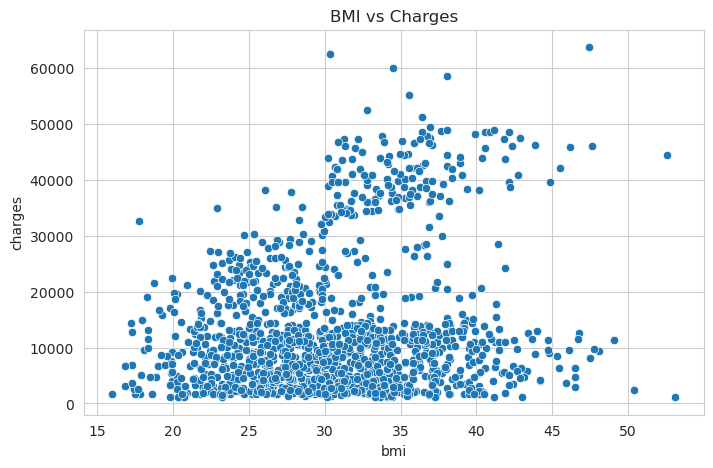

In [22]:
plt.figure(figsize=(8,5))
sns.scatterplot(x="bmi", y="charges", data=df)
plt.title("BMI vs Charges")
plt.show()

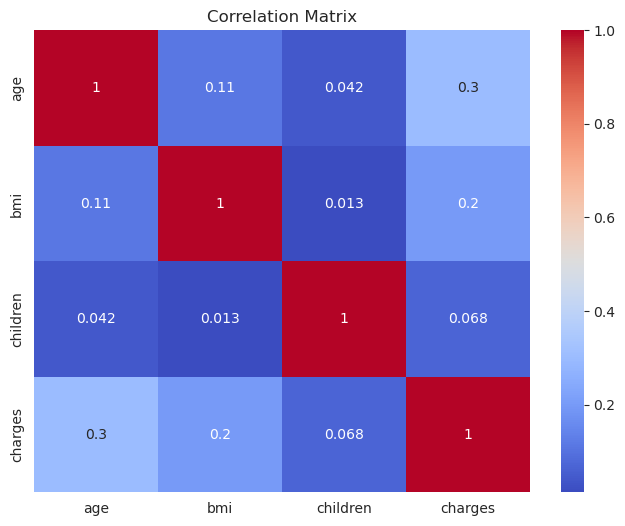

In [23]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(8,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

# Tak 4: Data Preprocessing

Machine learning algorithms require numerical inputs.

The categorical variables:

- sex
- smoker
- region

must be converted into numerical values.

We use One-Hot Encoding (Dummy Variables) to transform categorical features into a format suitable for Linear Regression.

In [24]:
# Convert categorical variables
df_encoded = pd.get_dummies(df, drop_first=True)

df_encoded.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


# Task 5: Defining Features and Target Variable

Features (X) are used to make predictions.

Target Variable (y) is the value we want to predict.

In this case:

- X = All predictor variables
- y = charges

In [25]:
X = df_encoded.drop("charges", axis=1)
y = df_encoded["charges"]

print(X.head())
print(y.head())

   age     bmi  children  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0     False        True             False   
1   18  33.770         1      True       False             False   
2   28  33.000         3      True       False             False   
3   33  22.705         0      True       False              True   
4   32  28.880         0      True       False              True   

   region_southeast  region_southwest  
0             False              True  
1              True             False  
2              True             False  
3             False             False  
4             False             False  
0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64


# Task 6: Train-Test Split

The dataset is divided into:

- Training Set (80%)
- Testing Set (20%)

The training data is used to train the model, while the testing data is used to evaluate model performance on unseen data.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)

Training Set: (1070, 8)
Testing Set: (268, 8)


# Task 7: Training the Linear Regression Model

Linear Regression attempts to find the best linear relationship between the features and medical insurance charges.

In [27]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model Training Complete")

Model Training Complete


# Task 8: Making Predictions

After training the model, we use the testing dataset to predict insurance charges.

In [28]:
y_pred = model.predict(X_test)

predictions = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

predictions.head()

,Actual,Predicted
764,9095.06825,8969.550274
887,5272.17580,7068.747443
890,29330.98315,36858.410912
1293,9301.89355,9454.678501
259,33750.29180,26973.173457


# Task 9: Model Evaluation

We evaluate the model using:

- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R² Score

A higher R² score indicates better predictive performance.

In [29]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE : 4181.194473753649
MSE : 33596915.851361446
RMSE: 5796.284659276272
R² Score: 0.7835929767120724


## Evaluation Results

The R² score indicates how much variation in insurance charges is explained by the model.

An R² score close to 1 means the model predicts medical insurance charges effectively.

The error metrics (MAE, MSE, RMSE) measure the difference between actual and predicted values. Lower values indicate better model performance.

# Task 10: Reflection

## 1. Which variables most strongly influence medical insurance charges?

The most influential variables are:

- Smoking status
- Age
- BMI

Smoking status appears to have the strongest impact because smokers consistently show much higher insurance charges than non-smokers.

## 2. Why might smoking affect insurance costs?

Smoking increases the risk of serious health conditions such as:

- Heart disease
- Lung disease
- Cancer

Insurance companies expect higher medical expenses for smokers, resulting in higher premiums and charges.

## 3. What improvements could be made to the model?

Possible improvements include:

- Using feature scaling
- Removing outliers
- Feature engineering
- Trying more advanced algorithms such as:
  - Random Forest Regression
  - Gradient Boosting
  - XGBoost

These techniques may improve prediction accuracy beyond simple Linear Regression.